# OFDM TX/RX — Benchmark LS vs SVR com BER + erro de reconstrução do sync

## 1) Imports


In [1]:
import os, sys, time, json, subprocess, re
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

## 2) Globais


In [2]:
WORKDIR = os.getcwd()

# Use serial (avoid hackrf=0/1 ambiguity)
TX_SERIAL = "0000000000000000147c63dc36507a53"
RX_SERIAL = "0000000000000000b36863dc23727e13"
TX_HACKRF = f"hackrf=0"
RX_HACKRF = f"hackrf=1"

# Lower default sample rate to reduce USB overflow on shared bus
SAMP_RATE = 2000000
CENTER_FREQ = 907980000.0

TX_PAYLOAD = os.path.join(WORKDIR, "tx_payload.bin")
RX_PAYLOAD = os.path.join(WORKDIR, "rx_payload.bin")
RX_IQ_FILE = os.path.join(WORKDIR, "rx_iq.cfile")

# Legacy known-payload mode (kept for quick sanity checks)
KNOWN_TEXT = "Hello World\n"
KNOWN_REPEATS = 200
KNOWN_MIN_COUNT = 5

# Benchmark mode (robust BER via packet pairing)
USE_BENCHMARK = True
BENCH_SEED = 12345
BENCH_NUM_PACKETS = 200
BENCH_PACKET_LEN = 50
BENCH_MAGIC = "OFDM"

# CRC: when enabled, RX only writes payload bytes for packets that pass CRC.
USE_CRC = False

# Estimadores a comparar
ESTIMATORS = ["ls", "svr"]

# Validation thresholds
RX_MIN_BYTES = 500
MIN_MATCHED_PACKETS = 50
RUN_TIMEOUT = 25

FATAL_STDERR_PATTERNS = [
    r"Buffer too small for min_noutput_items",
    r"thread_body_wrapper\s*:error",
]
OOOO_PATTERN = r"OOOO+"
WARN_STDERR_PATTERNS = [r"UUUU+"]

print("TX_PAYLOAD:", TX_PAYLOAD)
print("RX_PAYLOAD:", RX_PAYLOAD)

_RUNNER_PATH = os.path.join(WORKDIR, "ofdm_runner_crc_benchmark_final.py")


TX_PAYLOAD: /home/pesquisa/HEst_Prototyping/tx_payload.bin
RX_PAYLOAD: /home/pesquisa/HEst_Prototyping/rx_payload.bin


## 3) Funções para chamar o runner corrigido

In [3]:
def stderr_has(patterns, stderr_text):
    for pat in patterns:
        if re.search(pat, stderr_text or "", flags=re.IGNORECASE):
            return True
    return False

def run_experiment_subprocess(
    seconds=6.0,
    noise_voltage=0.0,
    record_iq=False,
    tx_args=None,
    rx_args=None,
    use_crc=None,
    use_benchmark=None,
    samp_rate=None,
    seed=None,
    num_packets=None,
    packet_len=None,
    magic=None,
    estimator="ls",
    extra_args=None,
    timeout=None,
):
    if tx_args is None:
        tx_args = TX_HACKRF
    if rx_args is None:
        rx_args = RX_HACKRF
    if use_crc is None:
        use_crc = USE_CRC
    if use_benchmark is None:
        use_benchmark = USE_BENCHMARK
    if samp_rate is None:
        samp_rate = SAMP_RATE
    if timeout is None:
        timeout = max(RUN_TIMEOUT, int(seconds) + 15)

    cmd = [sys.executable, _RUNNER_PATH,
           "--seconds", str(seconds),
           "--noise_voltage", str(noise_voltage),
           "--tx_args", tx_args,
           "--rx_args", rx_args,
           "--samp_rate", str(samp_rate),
           "--estimator", str(estimator)]

    if use_crc:
        cmd.append("--use_crc")
    if record_iq:
        cmd.append("--record_iq")

    if use_benchmark:
        cmd.append("--use_benchmark")
        cmd.extend(["--seed", str(BENCH_SEED if seed is None else seed)])
        cmd.extend(["--num_packets", str(BENCH_NUM_PACKETS if num_packets is None else num_packets)])
        cmd.extend(["--packet_len", str(BENCH_PACKET_LEN if packet_len is None else packet_len)])
        cmd.extend(["--magic", str(BENCH_MAGIC if magic is None else magic)])
    else:
        cmd.extend(["--known_text", KNOWN_TEXT, "--known_repeats", str(KNOWN_REPEATS), "--write_known"])

    if extra_args:
        cmd.extend(extra_args)

    try:
        p = subprocess.run(cmd, capture_output=True, text=True, timeout=timeout)
        stdout = p.stdout
        stderr = p.stderr
        returncode = p.returncode
        timeout_hit = False
    except subprocess.TimeoutExpired as e:
        stdout = e.stdout or ""
        stderr = (e.stderr or "") + f"\n[TIMEOUT after {timeout}s]"
        returncode = -9
        timeout_hit = True

    result = None
    for line in stdout.splitlines()[::-1]:
        line = line.strip()
        if not line:
            continue
        try:
            result = json.loads(line)
            break
        except Exception:
            continue

    return {
        "returncode": returncode,
        "stdout": stdout,
        "stderr": stderr,
        "result": result,
        "timeout_hit": timeout_hit,
        "cmd": cmd,
    }

def validate_run(run):
    res = run.get("result")
    if run.get("timeout_hit", False):
        return (False, "runner excedeu timeout")
    if res is None:
        return (False, "runner não retornou JSON")
    if run["returncode"] != 0:
        return (False, f"returncode != 0 ({run['returncode']})")
    if not res.get("ok", False):
        return (False, "runner capturou exceção ao rodar flowgraphs")

    stderr = run.get("stderr", "") or ""

    if stderr_has(FATAL_STDERR_PATTERNS, stderr):
        return (False, "stderr contém erro fatal (buffer/thread)")

    rx_size = int(res.get("rx_size", 0) or 0)
    matched = res.get("matched_packets")
    matched = int(matched) if matched is not None else 0

    has_oooo = re.search(OOOO_PATTERN, stderr, flags=re.IGNORECASE) is not None
    if has_oooo:
        if (matched < MIN_MATCHED_PACKETS) or (rx_size < RX_MIN_BYTES):
            return (False, f"overflow (OOOO) e pouca decodificação útil (matched={matched}, rx_size={rx_size})")

    if res.get("use_benchmark", False):
        if rx_size < RX_MIN_BYTES:
            return (False, f"rx_size muito pequeno ({rx_size})")
        if matched < MIN_MATCHED_PACKETS:
            return (False, f"matched_packets muito pequeno ({matched})")
    else:
        if rx_size < RX_MIN_BYTES:
            return (False, f"rx_size muito pequeno ({rx_size})")
        if int(res.get("known_pattern_count_in_rx_head", 0) or 0) < KNOWN_MIN_COUNT:
            return (False, f"padrão conhecido apareceu pouco (count={res.get('known_pattern_count_in_rx_head', 0)})")

    if has_oooo:
        return (True, "válido (com warning: OOOO)")
    if stderr_has(WARN_STDERR_PATTERNS, stderr):
        return (True, "válido (com warning: UUUU)")
    return (True, "válido")

def run_with_retries(max_tries=5, sleep_between=0.1, estimator="ls", **kwargs):
    last = None
    for k in range(1, max_tries + 1):
        run = run_experiment_subprocess(estimator=estimator, **kwargs)
        last = run
        ok, reason = validate_run(run)
        print(f"[{estimator}] [try {k}/{max_tries}] {reason}")
        if ok:
            run["validation_reason"] = reason
            return run
        time.sleep(sleep_between)
    last["validation_reason"] = "falhou após retries"
    return last


## 5) Sanity check (sem ruído) + diagnóstico (offset, BER alinhado)


In [4]:
def hexdump(b: bytes, n=64):
    b = b or b""
    h = " ".join(f"{x:02x}" for x in b[:n])
    a = "".join(chr(x) if 32 <= x < 127 else "." for x in b[:n])
    return f"{h}\n|{a}|"

def ber_bits(tx: bytes, rx: bytes):
    n = min(len(tx), len(rx))
    if n == 0:
        return None
    a = np.frombuffer(tx[:n], dtype=np.uint8)
    b = np.frombuffer(rx[:n], dtype=np.uint8)
    x = np.bitwise_xor(a, b)
    return float(np.unpackbits(x).sum()) / float(n * 8)

def safe_text(b: bytes, n=160):
    return (b or b"").decode("utf-8", errors="replace")[:n]


In [5]:
run0 = run_with_retries(
    max_tries=5,
    seconds=6.0,
    noise_voltage=0.0,
    record_iq=False,
    use_benchmark=USE_BENCHMARK,
    use_crc=USE_CRC,
    samp_rate=SAMP_RATE,
    estimator="ls",
)
print("validation:", run0.get("validation_reason"))
print("stderr tail:")
print("\n".join((run0.get("stderr","") or "").splitlines()[-10:]))

res0 = run0.get("result")
print(json.dumps(res0, indent=2) if res0 else "<no result>")

if res0:
    print("estimator:", res0.get("estimator"))
    print("use_crc:", res0.get("use_crc"), "use_benchmark:", res0.get("use_benchmark"))
    print("TX head hex:", res0.get("tx_head_hex"))
    print("RX head hex:", res0.get("rx_head_hex"))
    print("RX size:", res0.get("rx_size"), "TX size:", res0.get("tx_size"))
    print("sync_mse:", res0.get("sync_mse"))
    print("sync_nmse:", res0.get("sync_nmse"))
    print("sync_metric_frames:", res0.get("sync_metric_frames"))

    if res0.get("use_benchmark"):
        print("rx_packets_parsed:", res0.get("rx_packets_parsed"))
        print("matched_packets:", res0.get("matched_packets"))
        print("missing_packets:", res0.get("missing_packets"))
        print("BER (por pacotes):", res0.get("ber_packets"))
    else:
        print("offset:", res0.get("offset"), "score:", res0.get("score"))
        print("BER bruto:", res0.get("ber_raw"))
        print("BER alinhado:", res0.get("ber_aligned"))


[ls] [try 1/5] overflow (OOOO) e pouca decodificação útil (matched=0, rx_size=30)
[ls] [try 2/5] overflow (OOOO) e pouca decodificação útil (matched=0, rx_size=0)
[ls] [try 3/5] overflow (OOOO) e pouca decodificação útil (matched=0, rx_size=0)
[ls] [try 4/5] overflow (OOOO) e pouca decodificação útil (matched=0, rx_size=0)
[ls] [try 5/5] válido (com warning: UUUU)
validation: válido (com warning: UUUU)
stderr tail:
gr-osmosdr 0.2.0.0 (0.2.0) gnuradio 3.10.11.0
built-in source types: file fcd rtl rtl_tcp uhd hackrf rfspace airspy soapy redpitaya 
Using HackRF One with firmware v2.0.0
gr-osmosdr 0.2.0.0 (0.2.0) gnuradio 3.10.11.0
built-in sink types: uhd hackrf soapy redpitaya file 
Using HackRF One with firmware v2.0.1
UUUU
{
  "ok": true,
  "estimator": "ls",
  "seconds": 6.0,
  "noise_voltage": 0.0,
  "samp_rate": 2000000.0,
  "use_crc": false,
  "use_benchmark": true,
  "benchmark_seed": 12345,
  "benchmark_num_packets": 200,
  "benchmark_packet_len": 50,
  "benchmark_magic": "OFDM",

## 6) Varredura BER vs SNR + erro de reconstrução do sync (LS vs SVR)

In [6]:
def snr_db_to_noise_voltage(snr_db):
    return 10 ** (-snr_db / 20.0)

def _safe_mean_std(values):
    arr = np.array([np.nan if v is None else v for v in values], dtype=float)
    if arr.size == 0 or np.all(np.isnan(arr)):
        return np.nan, np.nan
    return float(np.nanmean(arr)), float(np.nanstd(arr))

def _safe_mean(values):
    arr = np.array([np.nan if v is None else v for v in values], dtype=float)
    if arr.size == 0 or np.all(np.isnan(arr)):
        return np.nan
    return float(np.nanmean(arr))

def sweep_estimator(estimator, snr_db_list, seconds=6.0, repetitions=3, max_tries=5, use_crc=None, use_benchmark=None):
    if use_crc is None:
        use_crc = USE_CRC
    if use_benchmark is None:
        use_benchmark = USE_BENCHMARK

    rows = []
    for snr_db in snr_db_list:
        nv = snr_db_to_noise_voltage(snr_db)

        bers = []
        sync_mses = []
        sync_nmses = []
        matcheds = []
        missings = []
        parsed = []
        valids = 0

        for _ in range(repetitions):
            run = run_with_retries(
                max_tries=max_tries,
                seconds=seconds,
                noise_voltage=nv,
                record_iq=False,
                use_crc=use_crc,
                use_benchmark=use_benchmark,
                samp_rate=SAMP_RATE,
                estimator=estimator,
            )
            ok, _ = validate_run(run)
            res = run.get("result") or {}
            if ok:
                valids += 1

            if use_benchmark:
                bers.append(res.get("ber_packets"))
                matcheds.append(res.get("matched_packets"))
                missings.append(res.get("missing_packets"))
                parsed.append(res.get("rx_packets_parsed"))
            else:
                bers.append(res.get("ber_aligned"))
                matcheds.append(None)
                missings.append(None)
                parsed.append(None)

            sync_mses.append(res.get("sync_mse"))
            sync_nmses.append(res.get("sync_nmse"))

        ber_mean, ber_std = _safe_mean_std(bers)
        sync_mse_mean, sync_mse_std = _safe_mean_std(sync_mses)
        sync_nmse_mean, sync_nmse_std = _safe_mean_std(sync_nmses)

        rows.append({
            "estimator": estimator,
            "snr_db": snr_db,
            "noise_voltage": nv,
            "valid_runs": valids,
            "ber_mean": ber_mean,
            "ber_std": ber_std,
            "sync_mse_mean": sync_mse_mean,
            "sync_mse_std": sync_mse_std,
            "sync_nmse_mean": sync_nmse_mean,
            "sync_nmse_std": sync_nmse_std,
            "matched_mean": _safe_mean(matcheds),
            "missing_mean": _safe_mean(missings),
            "rx_parsed_mean": _safe_mean(parsed),
        })
    return rows

def sweep_all(estimators, snr_db_list, seconds=6.0, repetitions=3, max_tries=5, use_crc=None, use_benchmark=None):
    out = {}
    for estimator in estimators:
        out[estimator] = sweep_estimator(
            estimator=estimator,
            snr_db_list=snr_db_list,
            seconds=seconds,
            repetitions=repetitions,
            max_tries=max_tries,
            use_crc=use_crc,
            use_benchmark=use_benchmark,
        )
    return out


In [7]:
snr_db_list = [30, 25, 20, 15, 10, 5]
results = sweep_all(
    ESTIMATORS,
    snr_db_list,
    seconds=2,
    repetitions=5,
    max_tries=8,
    use_crc=USE_CRC,
    use_benchmark=USE_BENCHMARK,
)
results


[ls] [try 1/8] válido (com warning: UUUU)
[ls] [try 1/8] válido (com warning: UUUU)
[ls] [try 1/8] válido (com warning: UUUU)
[ls] [try 1/8] válido (com warning: UUUU)
[ls] [try 1/8] válido (com warning: UUUU)
[ls] [try 1/8] válido (com warning: UUUU)
[ls] [try 1/8] overflow (OOOO) e pouca decodificação útil (matched=0, rx_size=0)
[ls] [try 2/8] válido (com warning: UUUU)
[ls] [try 1/8] overflow (OOOO) e pouca decodificação útil (matched=0, rx_size=0)
[ls] [try 2/8] overflow (OOOO) e pouca decodificação útil (matched=0, rx_size=0)
[ls] [try 3/8] válido (com warning: UUUU)
[ls] [try 1/8] válido (com warning: UUUU)
[ls] [try 1/8] válido (com warning: UUUU)
[ls] [try 1/8] overflow (OOOO) e pouca decodificação útil (matched=0, rx_size=0)
[ls] [try 2/8] válido (com warning: UUUU)
[ls] [try 1/8] overflow (OOOO) e pouca decodificação útil (matched=0, rx_size=0)
[ls] [try 2/8] válido (com warning: UUUU)
[ls] [try 1/8] válido (com warning: UUUU)
[ls] [try 1/8] overflow (OOOO) e pouca decodifica

{'ls': [{'estimator': 'ls',
   'snr_db': 30,
   'noise_voltage': 0.03162277660168379,
   'valid_runs': 5,
   'ber_mean': 0.010765453106806308,
   'ber_std': 0.0006739326023068443,
   'sync_mse_mean': 0.0,
   'sync_mse_std': 0.0,
   'sync_nmse_mean': 0.0,
   'sync_nmse_std': 0.0,
   'matched_mean': 191.8,
   'missing_mean': 8.2,
   'rx_parsed_mean': 1296.6},
  {'estimator': 'ls',
   'snr_db': 25,
   'noise_voltage': 0.05623413251903491,
   'valid_runs': 5,
   'ber_mean': 0.010823893567818755,
   'ber_std': 0.0002797807681131132,
   'sync_mse_mean': 0.0,
   'sync_mse_std': 0.0,
   'sync_nmse_mean': 0.0,
   'sync_nmse_std': 0.0,
   'matched_mean': 192.8,
   'missing_mean': 7.2,
   'rx_parsed_mean': 1297.2},
  {'estimator': 'ls',
   'snr_db': 20,
   'noise_voltage': 0.1,
   'valid_runs': 5,
   'ber_mean': 0.012299724979105389,
   'ber_std': 0.0008442518144687809,
   'sync_mse_mean': 0.0,
   'sync_mse_std': 0.0,
   'sync_nmse_mean': 0.0,
   'sync_nmse_std': 0.0,
   'matched_mean': 192.6,
  

## 7) Gráficos finais

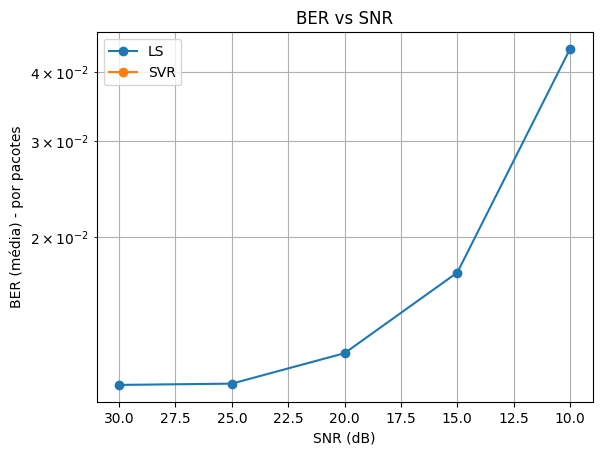

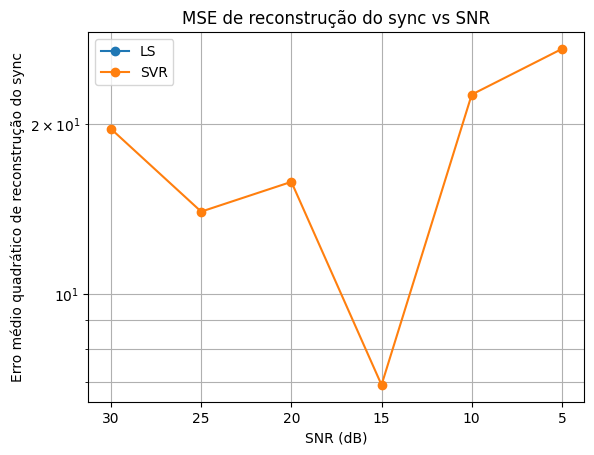

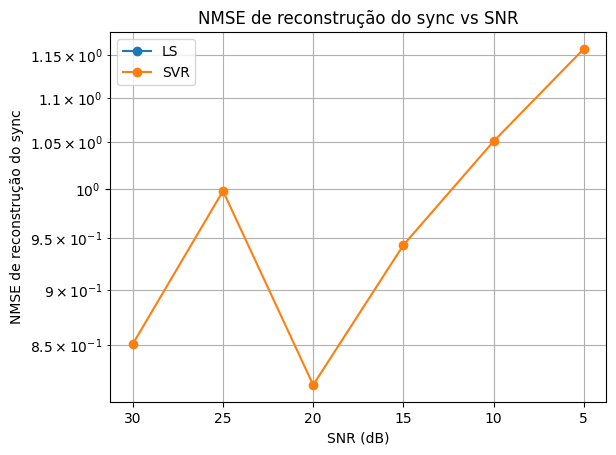

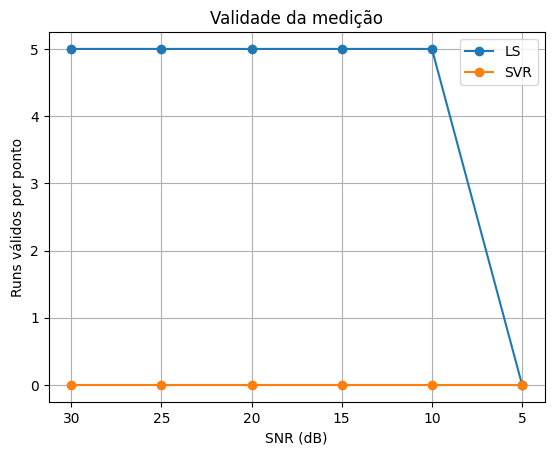

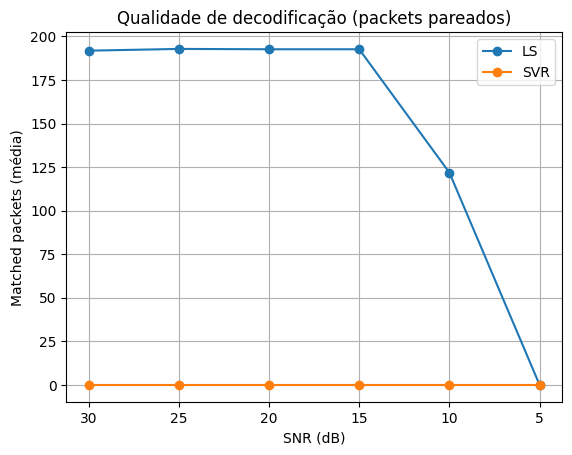

In [8]:
plt.figure()
for estimator in ESTIMATORS:
    rows = results[estimator]
    snr = [r["snr_db"] for r in rows]
    ber = [r["ber_mean"] for r in rows]
    plt.semilogy(snr, ber, marker="o", label=estimator.upper())
plt.gca().invert_xaxis()
plt.grid(True, which="both")
plt.xlabel("SNR (dB)")
plt.ylabel("BER (média) - por pacotes" if USE_BENCHMARK else "BER (alinhado) - média")
plt.title("BER vs SNR")
plt.legend()
plt.show()

plt.figure()
for estimator in ESTIMATORS:
    rows = results[estimator]
    snr = [r["snr_db"] for r in rows]
    sync_mse = [r["sync_mse_mean"] for r in rows]
    plt.semilogy(snr, sync_mse, marker="o", label=estimator.upper())
plt.gca().invert_xaxis()
plt.grid(True, which="both")
plt.xlabel("SNR (dB)")
plt.ylabel("Erro médio quadrático de reconstrução do sync")
plt.title("MSE de reconstrução do sync vs SNR")
plt.legend()
plt.show()

plt.figure()
for estimator in ESTIMATORS:
    rows = results[estimator]
    snr = [r["snr_db"] for r in rows]
    sync_nmse = [r["sync_nmse_mean"] for r in rows]
    plt.semilogy(snr, sync_nmse, marker="o", label=estimator.upper())
plt.gca().invert_xaxis()
plt.grid(True, which="both")
plt.xlabel("SNR (dB)")
plt.ylabel("NMSE de reconstrução do sync")
plt.title("NMSE de reconstrução do sync vs SNR")
plt.legend()
plt.show()

plt.figure()
for estimator in ESTIMATORS:
    rows = results[estimator]
    snr = [r["snr_db"] for r in rows]
    valids = [r["valid_runs"] for r in rows]
    plt.plot(snr, valids, marker="o", label=estimator.upper())
plt.gca().invert_xaxis()
plt.grid(True)
plt.xlabel("SNR (dB)")
plt.ylabel("Runs válidos por ponto")
plt.title("Validade da medição")
plt.legend()
plt.show()

if USE_BENCHMARK:
    plt.figure()
    for estimator in ESTIMATORS:
        rows = results[estimator]
        snr = [r["snr_db"] for r in rows]
        matched = [r["matched_mean"] for r in rows]
        plt.plot(snr, matched, marker="o", label=estimator.upper())
    plt.gca().invert_xaxis()
    plt.grid(True)
    plt.xlabel("SNR (dB)")
    plt.ylabel("Matched packets (média)")
    plt.title("Qualidade de decodificação (packets pareados)")
    plt.legend()
    plt.show()
